# Churn Prediction → Personalised Retention Actions
**Amit Gajbhiye · a worked example on a simulated multi-vertical delivery app · synthetic data only**

**Question.** Which users are about to stop ordering across food, grocery and retail, and *which* retention action should each one get, if any?

Predicting churn is the easy half. The decision that costs money is the action, and **the users most likely to churn are not always the ones an action saves**. Some would stay anyway, and some are lost whatever we do. So the notebook does three things:

1. **Risk model.** Predicts who churns in the next 28 days, validated on a *later* time window.
2. **Uplift model.** Estimates, for each user, how much each action (discount, service recovery, cross-sell into a new vertical) lowers their churn probability. It learns from a randomised campaign.
3. **Policy.** Picks the action with the best expected net value per user (or none), evaluates that choice offline on a *second* randomised campaign, and then designs the online A/B test.

**Churn definition.** An active user (at least one order in the last 60 days) who places **no order in the next 28 days**, across all verticals combined.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 7
DATA = Path("data")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

orders = pd.read_csv(DATA / "orders.csv.gz")
users = pd.read_csv(DATA / "users.csv")
campaigns = pd.read_csv(DATA / "campaigns.csv")
print(f"{len(orders):,} orders | {len(users):,} users | {len(campaigns):,} campaign assignments")
orders.head()

714,864 orders | 50,000 users | 77,201 campaign assignments


,user_id,day,vertical,order_value_aed,discount_used,delivery_delay_min,rating
0,6,0,food,23.36,0,27.6,4
1,25,0,food,61.76,1,36.8,3
2,28,0,food,41.83,0,13.0,5
3,36,0,food,82.27,1,31.8,5
4,39,0,food,42.60,0,25.6,4


## 1. Features and labels, with a hard time boundary
Features use **only orders on or before the cutoff day**. The label uses only the 28 days after it. The model is trained at cutoff day 90 and tested at cutoff day 120, so every test prediction is about a future period the model never saw. A random row split would leak each user's own future into training.

The features cover recency and frequency, the frequency trend, **cross-vertical breadth** (how many of food, grocery and retail the user orders from), basket value, reliance on discounts, and service quality: late deliveries and low ratings.

In [2]:
ARMS = ["control", "discount", "service_recovery", "cross_sell"]
COST_AED = {"control": 0, "discount": 15, "service_recovery": 10, "cross_sell": 5}
MARGIN = 0.25          # contribution margin on order value (assumption)
LATE_MIN = 35


def build(cutoff: int) -> pd.DataFrame:
    past = orders[orders.day <= cutoff]
    assert past.day.max() <= cutoff                       # leakage guard
    pop = campaigns[campaigns.campaign_day == cutoff][["user_id", "arm"]]

    def window(days):
        return past[past.day > cutoff - days]

    w7, w28, w60 = window(7), window(28), window(60)
    prev28 = past[(past.day > cutoff - 56) & (past.day <= cutoff - 28)]
    f = pop.set_index("user_id")
    f["recency_days"] = cutoff - past.groupby("user_id").day.max()
    f["orders_7d"] = w7.groupby("user_id").size()
    f["orders_28d"] = w28.groupby("user_id").size()
    f["orders_60d"] = w60.groupby("user_id").size()
    f["trend_28d"] = f.orders_28d.fillna(0) - prev28.groupby("user_id").size().reindex(f.index).fillna(0)
    per_v = w60.pivot_table(index="user_id", columns="vertical", values="day", aggfunc="size")
    for v in ["food", "grocery", "retail"]:
        f[f"{v}_orders_60d"] = per_v.get(v)
    f["n_verticals_60d"] = w60.groupby("user_id").vertical.nunique()
    f["aov_60d"] = w60.groupby("user_id").order_value_aed.mean()
    f["discount_share_60d"] = w60.groupby("user_id").discount_used.mean()
    late = w28.assign(late=w28.delivery_delay_min > LATE_MIN)
    f["late_orders_28d"] = late.groupby("user_id").late.sum()
    f["late_share_28d"] = late.groupby("user_id").late.mean()
    f["avg_rating_28d"] = w28.groupby("user_id").rating.mean()
    f["low_ratings_28d"] = w28[w28.rating <= 2].groupby("user_id").size()
    f["avg_delay_28d"] = w28.groupby("user_id").delivery_delay_min.mean()
    u = users.set_index("user_id")
    f["tenure_days"] = cutoff - u.signup_day.reindex(f.index)
    f["city"] = u.city.reindex(f.index).astype("category")
    counts = [c for c in f.columns if c.startswith(("orders_", "late_orders", "low_ratings"))
              or c.endswith("_orders_60d") or c == "n_verticals_60d"]
    f[counts] = f[counts].fillna(0)
    future = orders[(orders.day > cutoff) & (orders.day <= cutoff + 28)].user_id.unique()
    f["churn_28d"] = (~f.index.isin(future)).astype(int)
    # value of keeping the user: margin on their expected orders over the next 90 days
    f["value_90d_aed"] = MARGIN * f.aov_60d.fillna(orders.order_value_aed.mean()) * np.maximum(
        f.orders_60d * 90 / 60, 1)
    return f.reset_index()


train, test = build(90), build(120)
FEATS = [c for c in train.columns if c not in ("user_id", "arm", "churn_28d", "value_90d_aed")]
print(f"train (cutoff 90): {len(train):,} users, churn {train.churn_28d.mean():.1%}")
print(f"test  (cutoff 120): {len(test):,} users, churn {test.churn_28d.mean():.1%}")
train.groupby("arm").churn_28d.agg(["size", "mean"]).round(3)

train (cutoff 90): 40,591 users, churn 28.8%
test  (cutoff 120): 36,610 users, churn 25.0%


,size,mean
arm,,
control,10182,0.318
cross_sell,10113,0.279
discount,10131,0.255
service_recovery,10165,0.298


## 2. Churn risk model
A gradient-boosted classifier trained on all day-90 users, with the campaign arm as a feature so that campaign effects are not mistaken for natural risk. It is compared against a logistic-regression baseline on recency, frequency and tenure. Both are scored on **untreated (control) users in the later window**, and the boosted model predicts them with arm = control.

In [3]:
ARM_T = pd.CategoricalDtype(ARMS)
for d in (train, test):
    d["arm"] = d["arm"].astype(ARM_T)
RISK_FEATS = FEATS + ["arm"]
te_c = test[test.arm == "control"]


def gbm(**kw):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=80, l2_regularization=2.0,
                                          categorical_features="from_dtype", random_state=SEED,
                                          **kw)


hgb = gbm().fit(train[RISK_FEATS], train.churn_28d)

RFM = ["recency_days", "orders_60d", "tenure_days"]
rfm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rfm.fit(train[RFM].fillna(0), train.churn_28d)


def lift_at(y, p, frac=0.1):
    k = int(len(y) * frac)
    return y[np.argsort(-p)[:k]].mean() / y.mean()


y = te_c.churn_28d.to_numpy()
p_hgb = hgb.predict_proba(te_c[RISK_FEATS])[:, 1]
p_rfm = rfm.predict_proba(te_c[RFM].fillna(0))[:, 1]
risk_metrics = {}
for name, p in [("RFM logistic baseline", p_rfm), ("Gradient boosting (all features)", p_hgb)]:
    risk_metrics[name] = {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
                          "brier": brier_score_loss(y, p), "top_decile_lift": lift_at(y, p)}
pd.DataFrame(risk_metrics).T.round(3)

,roc_auc,pr_auc,brier,top_decile_lift
RFM logistic baseline,0.819,0.663,0.145,2.863
Gradient boosting (all features),0.834,0.682,0.139,2.945


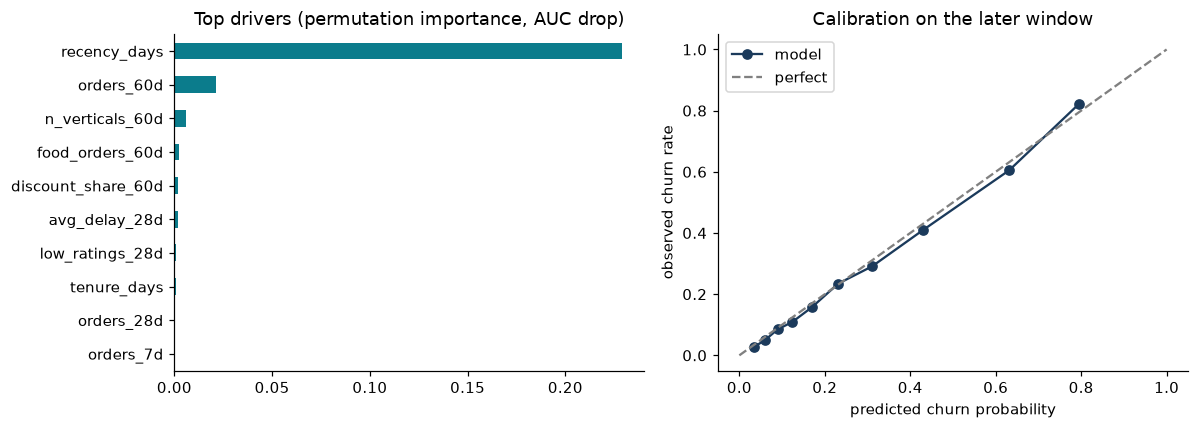

In [4]:
imp = permutation_importance(hgb, te_c[RISK_FEATS], y, scoring="roc_auc", n_repeats=5,
                             random_state=SEED)
importance = pd.Series(imp.importances_mean, index=RISK_FEATS).drop("arm").sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
importance.tail(10).plot.barh(ax=ax[0], color="#0B7C8C")
ax[0].set_title("Top drivers (permutation importance, AUC drop)")
bins = pd.qcut(p_hgb, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"p": p_hgb, "y": y, "b": bins}).groupby("b").mean()
ax[1].plot(cal.p, cal.y, "o-", color="#1B3A5B", label="model")
ax[1].plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax[1].set(xlabel="predicted churn probability", ylabel="observed churn rate",
          title="Calibration on the later window")
ax[1].legend()
fig.tight_layout()
fig.savefig(OUT / "fig1_risk_model.png", bbox_inches="tight")

## 3. Uplift: which action changes the outcome for which user
The day-90 campaign assigned control, discount, service recovery or cross-sell **at random**, so the arms are directly comparable. A **T-learner** fits one churn model per arm. The uplift of action *a* for a user is P(churn | control) − P(churn | *a*).

**Validation on the later randomised campaign.** For each action, test users are split into thirds by *predicted* uplift. Within each third, the *observed* effect is churn in the control arm minus churn in that action's arm. If the model ranks users correctly, the observed effect should rise from the bottom third to the top. A secondary check uses the simulator's hidden traits, which are never used in modelling.

,action,predicted_uplift_third,predicted,observed
0,discount,low,-0.001,0.020
1,discount,mid,0.050,0.055
2,discount,high,0.138,0.088
3,service_recovery,low,-0.038,0.020
4,service_recovery,mid,0.018,0.006
5,service_recovery,high,0.078,0.035
6,cross_sell,low,-0.026,0.036
7,cross_sell,mid,0.029,0.031
8,cross_sell,high,0.103,0.068


discount uplift vs hidden price sensitivity (corr)               0.187
service-recovery uplift vs late orders in last 28d (corr)        0.220
cross-sell uplift: single-vertical minus multi-vertical users    0.056
dtype: float64


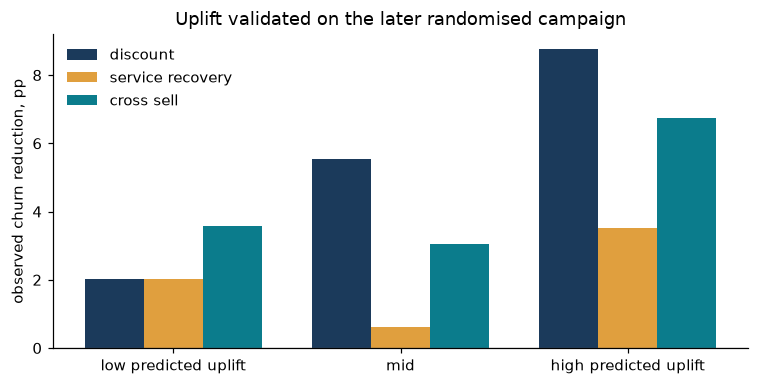

In [5]:
arm_models = {a: gbm().fit(train.loc[train.arm == a, FEATS], train.churn_28d[train.arm == a])
              for a in ARMS}

p_arm = pd.DataFrame({a: arm_models[a].predict_proba(test[FEATS])[:, 1] for a in ARMS},
                     index=test.index)
uplift = pd.DataFrame({a: p_arm["control"] - p_arm[a] for a in ARMS[1:]})

latent = pd.read_csv(DATA / "users_latent.csv").set_index("user_id")
chk = test[["user_id", "late_orders_28d", "n_verticals_60d"]].join(uplift)
chk["price_sensitivity"] = latent.price_sensitivity.reindex(chk.user_id).to_numpy()
sanity = {
    "discount uplift vs hidden price sensitivity (corr)":
        chk.discount.corr(chk.price_sensitivity),
    "service-recovery uplift vs late orders in last 28d (corr)":
        chk.service_recovery.corr(chk.late_orders_28d),
    "cross-sell uplift: single-vertical minus multi-vertical users":
        chk[chk.n_verticals_60d <= 1].cross_sell.mean() - chk[chk.n_verticals_60d > 1].cross_sell.mean(),
}
rows = []
for a in ARMS[1:]:
    third = pd.qcut(uplift[a], 3, labels=["low", "mid", "high"])
    for t in ["low", "mid", "high"]:
        g = test[third == t]
        rows.append({"action": a, "predicted_uplift_third": t,
                     "predicted": uplift[a][third == t].mean(),
                     "observed": g[g.arm == "control"].churn_28d.mean() - g[g.arm == a].churn_28d.mean()})
uplift_check = pd.DataFrame(rows)
display(uplift_check.round(3))
print(pd.Series(sanity).round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.26
for i, a in enumerate(ARMS[1:]):
    d = uplift_check[uplift_check.action == a]
    ax.bar(np.arange(3) + (i - 1) * w, d.observed * 100, w, label=a.replace("_", " "),
           color=["#1B3A5B", "#E09F3E", "#0B7C8C"][i])
ax.set_xticks(range(3), ["low predicted uplift", "mid", "high predicted uplift"])
ax.set_ylabel("observed churn reduction, pp")
ax.set_title("Uplift validated on the later randomised campaign")
ax.axhline(0, color="grey", lw=0.8)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "fig3_uplift_validation.png", bbox_inches="tight")

## 4. Policy: the best action per user, evaluated on a *different* randomised campaign
The expected net gain of action *a* for a user is `uplift_a × value_90d − cost_a`, where `value_90d` is the margin on the orders we expect from that user over the next 90 days. Each user gets the action with the highest positive net gain, or no action if none is positive.

**Offline evaluation.** The day-120 campaign was also randomised, with probability 1/4 per arm. So the value of *any* policy can be estimated without bias by inverse propensity weighting: keep the users whose random arm happens to match what the policy would have chosen, and weight each by 4. The comparison is against simple rules a team might use today. Confidence intervals come from 500 bootstrap resamples.

In [6]:
net = pd.DataFrame({a: uplift[a] * test.value_90d_aed - COST_AED[a] for a in ARMS[1:]})
best = net.idxmax(axis=1).where(net.max(axis=1) > 0, "control")

risk_all = pd.Series(hgb.predict_proba(test[RISK_FEATS].assign(
    arm=pd.Categorical(["control"] * len(test), dtype=ARM_T)))[:, 1], index=test.index)
rng = np.random.default_rng(SEED)
policies = {
    "No action": pd.Series("control", index=test.index),
    "Discount to everyone": pd.Series("discount", index=test.index),
    "Discount to top-30% risk": pd.Series(np.where(risk_all >= risk_all.quantile(0.7),
                                                   "discount", "control"), index=test.index),
    "Random action": pd.Series(rng.choice(ARMS, len(test)), index=test.index),
    "Uplift policy (this notebook)": best,
}

arm = test.arm.astype(str).to_numpy()
churn = test.churn_28d.to_numpy()
value = test.value_90d_aed.to_numpy()


def evaluate(assign, idx):
    match = (arm[idx] == assign[idx]) * 4.0          # IPS weight, propensity 1/4
    cost = pd.Series(assign[idx]).map(COST_AED).to_numpy()
    churn_rate = np.mean(match * churn[idx])
    net_value = np.mean(match * ((1 - churn[idx]) * value[idx] - cost))
    return churn_rate, net_value, cost.mean()


all_idx = np.arange(len(test))
boot = [rng.integers(0, len(test), len(test)) for _ in range(500)]
rows = []
for name, pol in policies.items():
    a = pol.to_numpy()
    cr, nv, c = evaluate(a, all_idx)
    bs = np.array([evaluate(a, b)[1] - evaluate(policies["No action"].to_numpy(), b)[1]
                   for b in boot])
    rows.append({"policy": name, "churn_rate": cr, "spend_per_user_aed": c,
                 "net_value_per_user_aed": nv,
                 "incremental_value_per_1k_users_aed": 1000 * (nv - evaluate(
                     policies["No action"].to_numpy(), all_idx)[1]),
                 "ci_low": 1000 * np.percentile(bs, 2.5), "ci_high": 1000 * np.percentile(bs, 97.5)})
results = pd.DataFrame(rows).set_index("policy")
mix = best.value_counts(normalize=True).round(3)
display(results.round(3))
print("Uplift policy action mix:", mix.to_dict())

,churn_rate,spend_per_user_aed,net_value_per_user_aed,incremental_value_per_1k_users_aed,ci_low,ci_high
policy,,,,,,
No action,0.279,0.000,139.228,0.000,0.000,0.000
Discount to everyone,0.228,15.000,129.986,-9241.302,-15076.567,-3603.226
Discount to top-30% risk,0.259,4.500,137.175,-2052.869,-3264.914,-937.639
Random action,0.254,7.495,134.480,-4747.224,-9512.374,-178.314
Uplift policy (this notebook),0.259,3.121,142.204,2975.995,-1042.721,7618.418


Uplift policy action mix: {'control': 0.596, 'cross_sell': 0.256, 'service_recovery': 0.077, 'discount': 0.072}


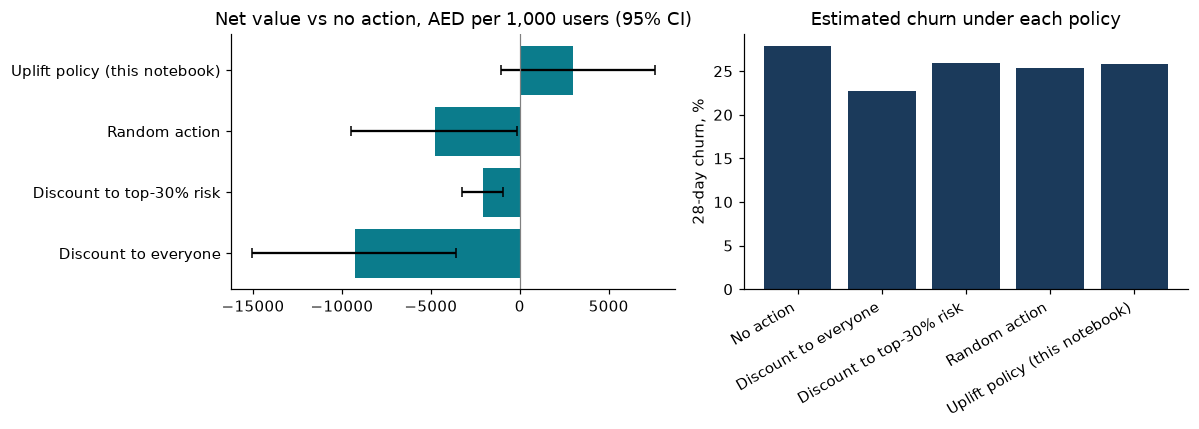

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
r = results.drop("No action")
ax[0].barh(r.index, r.incremental_value_per_1k_users_aed, color="#0B7C8C",
           xerr=[r.incremental_value_per_1k_users_aed - r.ci_low,
                 r.ci_high - r.incremental_value_per_1k_users_aed], capsize=3)
ax[0].axvline(0, color="grey", lw=0.8)
ax[0].set_title("Net value vs no action, AED per 1,000 users (95% CI)")
ax[1].bar(results.index, results.churn_rate * 100, color="#1B3A5B")
ax[1].set_ylabel("28-day churn, %")
ax[1].set_title("Estimated churn under each policy")
ax[1].tick_params(axis="x", rotation=30)
for lbl in ax[1].get_xticklabels():
    lbl.set_ha("right")
fig.tight_layout()
fig.savefig(OUT / "fig2_policies.png", bbox_inches="tight")

## 5. The online test that should come next
Offline results on a simulator justify a test. They don't justify a launch. The rollout design:

* **Randomisation unit:** the user, split by a stable hash of the user ID, stratified by city and by number of verticals used.
* **Arms:** (A) the current rule, "discount to top-30% risk", versus (B) the uplift policy. A small untreated holdout keeps measuring uplift itself.
* **Primary metric:** 28-day retention (at least one order in any vertical).
* **Guardrails:** incentive spend per user, contribution margin per user, order value, delivery complaints, and unsubscribe rates on the channel used.
* **Duration:** one full 28-day outcome window after the last user enters, with no peeking. Results are also read by city and by vertical breadth.

In [8]:
from statistics import NormalDist

p0 = results.loc["Discount to top-30% risk", "churn_rate"]
mde = 0.015                                        # absolute churn reduction worth detecting
z = NormalDist().inv_cdf
p1 = p0 - mde
n_per_arm = int(np.ceil((z(0.975) + z(0.8)) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / mde ** 2))
print(f"baseline churn {p0:.1%}, MDE {mde:.1%} abs -> {n_per_arm:,} users per arm "
      f"(alpha 0.05 two-sided, power 0.8)")

baseline churn 25.9%, MDE 1.5% abs -> 13,125 users per arm (alpha 0.05 two-sided, power 0.8)


## 6. Hand-off: metrics for the narrator
The metrics are exported as JSON. An LLM prompt (`narrator_prompt.md`) turns them into a short conclusion for stakeholders with recommendations, and is told to use only the numbers given. That is the "Experiment Narrator" idea, attached to a real result.

In [9]:
metrics = {
    "setup": {"users_train": len(train), "users_test": len(test),
              "churn_definition": "no order in any vertical in the 28 days after cutoff",
              "train_cutoff_day": 90, "test_cutoff_day": 120,
              "action_costs_aed": COST_AED, "margin_assumption": MARGIN,
              "value_horizon_days": 90,
              "data": "synthetic, simulated; not real company data"},
    "risk_model": {k: {m: round(v, 3) for m, v in d.items()} for k, d in risk_metrics.items()},
    "top_churn_drivers": importance.sort_values(ascending=False).head(5).round(4).to_dict(),
    "uplift_validation_on_later_rct": uplift_check.round(3).to_dict(orient="records"),
    "uplift_sanity_checks": {k: round(v, 3) for k, v in sanity.items()},
    "policies": results.round(3).reset_index().to_dict(orient="records"),
    "uplift_policy_action_mix": mix.to_dict(),
    "ab_test": {"baseline_churn": round(p0, 3), "mde_abs": mde, "users_per_arm": n_per_arm},
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics["policies"], indent=1)[:1200])

[
 {
  "policy": "No action",
  "churn_rate": 0.279,
  "spend_per_user_aed": 0.0,
  "net_value_per_user_aed": 139.228,
  "incremental_value_per_1k_users_aed": 0.0,
  "ci_low": 0.0,
  "ci_high": 0.0
 },
 {
  "policy": "Discount to everyone",
  "churn_rate": 0.228,
  "spend_per_user_aed": 15.0,
  "net_value_per_user_aed": 129.986,
  "incremental_value_per_1k_users_aed": -9241.302,
  "ci_low": -15076.567,
  "ci_high": -3603.226
 },
 {
  "policy": "Discount to top-30% risk",
  "churn_rate": 0.259,
  "spend_per_user_aed": 4.5,
  "net_value_per_user_aed": 137.175,
  "incremental_value_per_1k_users_aed": -2052.869,
  "ci_low": -3264.914,
  "ci_high": -937.639
 },
 {
  "policy": "Random action",
  "churn_rate": 0.254,
  "spend_per_user_aed": 7.495,
  "net_value_per_user_aed": 134.48,
  "incremental_value_per_1k_users_aed": -4747.224,
  "ci_low": -9512.374,
  "ci_high": -178.314
 },
 {
  "policy": "Uplift policy (this notebook)",
  "churn_rate": 0.259,
  "spend_per_user_aed": 3.121,
  "net_valu

## 7. Limits (read before trusting any number above)
* **The data is simulated.** The effects were planted, so recovering them shows the method works, not that real users behave this way.
* **Value is a 90-day margin proxy.** Discounts also cannibalise orders that would have happened anyway, and longer-term lifetime value and incentive fatigue are ignored.
* **The T-learner is the simplest uplift learner.** With real data I would compare it against X-learner or DR-learner variants and use Qini curves, and I would re-fit on each new campaign.
* **The policy is a daily batch decision.** A natural next step is session-level triggers, such as service recovery right after a late order, which matches the team's push towards real-time learning.